# 1 · The alert level that needs a big fleet

Simulate a small fleet, compute the classical alert level, and see how often it is degenerate. See [Lesson 1](../docs/lessons/01-the-alert-level-that-needs-a-big-fleet.md).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from smallfleet import plotting

plotting.use_style()
rng = np.random.default_rng(1)

In [2]:
from smallfleet.data_generation import simulate_history
from smallfleet.frequentist_baseline import (
    degenerate_baseline_probability,
    garwood_interval,
    mean_sd_alert_level,
    monthly_rates,
)

h = simulate_history(rng, rate=0.25, n_aircraft=5, fh_per_aircraft_month=35.0, months=24)
base = monthly_rates(h.counts[:12], h.exposure_fh[:12])
print("baseline counts:", h.counts[:12])
print("mean + 2 sd level:", mean_sd_alert_level(base, 2.0))
print("90 % interval, 24 months:", garwood_interval(h.total_count, h.total_exposure_fh, 0.90))
print("P(baseline sd = 0):", degenerate_baseline_probability(0.25, 175.0))

baseline counts: [0 0 0 0 0 0 0 0 0 0 0 0]
mean + 2 sd level: 0.0
90 % interval, 24 months: (0.012212689139892983, 1.1294915519977564)
P(baseline sd = 0): 0.5915553643668151


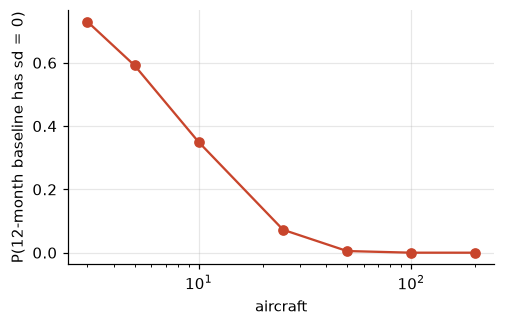

In [3]:
sizes = np.array([3, 5, 10, 25, 50, 100, 200])
p = [degenerate_baseline_probability(0.25, n * 35.0) for n in sizes]
fig, ax = plt.subplots(figsize=(5, 3))
ax.semilogx(sizes, p, "o-", color=plotting.FREQUENTIST_COLOR)
ax.set_xlabel("aircraft")
ax.set_ylabel("P(12-month baseline has sd = 0)");